# Système de recommandation hybride d'offres d'emploi — notebook unique
**Dataset : JTH – Job Tracking History** (Romero, Millet & Behar, RecSys'26, licence CC BY-NC 4.0, usage recherche non commercial).

Objectif : recommander à un candidat les offres d'emploi actives les plus pertinentes, en combinant trois moteurs
(**contenu**, **collaboratif**, **connaissances**) selon les **7 stratégies d'hybridation** de Burke, puis comparer
ces hybrides à chaque moteur seul et à une baseline de **popularité**, y compris en situation de **cold-start**.

Ce notebook est **autonome** : tout le code est dans les cellules ci-dessous.
* **Partie I — Code** : A. données · B. représentations · C. moteurs · D. hybrides · E. évaluation · F. explications
* **Partie II — Expériences** : 1. chargement · 2. analyse exploratoire · 3. découpage temporel · 4. moteurs ·
  5. réglage (validation) · 6. test · 7. cold-start · 8. interprétabilité · 9. démonstration

Données : si `data/` ne contient pas les 3 CSV, ils sont téléchargés depuis Zenodo (record 21390581) et vérifiés par SHA-256.
La démo web (Streamlit) reste un fichier séparé `app.py`, car Streamlit ne s'exécute qu'à partir d'un script `.py`.

In [1]:
import ast, os, re, time, warnings
from bisect import bisect_left
from collections import defaultdict
from dataclasses import dataclass, field
from pathlib import Path
import itertools

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, normalize

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)

# Partie I — Code

## A. Données : chargement, nettoyage, découpage temporel

Transforme les 3 CSV en interactions propres et répond à la question « que savait-on à la date t ? » sans jamais utiliser le futur. Le téléchargement depuis Zenodo (`ensure_jth`) n'a lieu que si les fichiers sont absents.

<details><summary>Notes de conception</summary>

```
data.py — Chargement, nettoyage et découpage temporel du dataset JTH.

JTH (Job Tracking History, Romero et al., RecSys'26, CC BY-NC 4.0) contient :
  - candidates.csv : profils des candidats (compétences, diplôme, expérience...)
  - jobs.csv       : offres d'emploi (compétences requises, exigences...)
  - history.csv    : une ligne = un couple candidat–offre et les dates des étapes
                     du processus de recrutement (candidature, entretiens, offre...).

Choix de modélisation : chaque ligne de history est une interaction implicite
positive (le candidat a été positionné sur l'offre). La date de l'interaction est
la première date non vide du processus (comme dans le découpage officiel JTH).
```
</details>

In [2]:
import ast
import re
from bisect import bisect_left
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd

# Colonnes de dates du processus de recrutement, dans l'ordre de l'entonnoir.
STAGE_COLS = [
    "spontaneous_application_date", "shortlist_date", "qualification_date",
    "resume_sent_to_company_date", "1st_interview_date", "2nd_interview_date",
    "3rd_interview_date", "4th_interview_date", "job_offer_proposed_date",
    "job_offer_accepted_date",
]
EPOCH = pd.Timestamp("1970-01-01")


# ---------------------------------------------------------------------------
# Parsing des champs « liste »
# ---------------------------------------------------------------------------
def parse_list(value) -> list[str]:
    """Transforme un champ texte en liste de jetons normalisés.

    Les champs JTH mélangent plusieurs formats : « a;b;c » (champs manuels),
    « ['a', 'b'] » (champs extraits par LLM) ou « a, b ». On gère les trois,
    on met en minuscules et on supprime la sentinelle `_rare_skill_`.
    """
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return []
    s = str(value).strip()
    if not s or s.lower() in {"nan", "none", "[]"}:
        return []
    items: list
    if s.startswith("["):
        try:
            items = list(ast.literal_eval(s))
        except (ValueError, SyntaxError):
            items = s.strip("[]").split(",")
    elif ";" in s:
        items = s.split(";")
    else:
        items = s.split(",")
    out = []
    for it in items:
        t = str(it).strip().strip("'\"").lower()
        t = re.sub(r"\s+", " ", t)
        if t and not t.startswith("_rare"):
            out.append(t)
    return out


def first_number(value) -> float:
    """Extrait le premier nombre d'un intervalle binné ('3-6 years' -> 3, '+6 years' -> 6)."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return np.nan
    m = re.search(r"\d+(\.\d+)?", str(value))
    return float(m.group()) if m else np.nan


def to_bool(value) -> float:
    """Booléen tolérant : True/False/'true'/'1' -> 1.0/0.0, sinon NaN (inconnu)."""
    if isinstance(value, (bool, np.bool_)):
        return float(value)
    s = str(value).strip().lower()
    if s in {"true", "1", "yes", "1.0"}:
        return 1.0
    if s in {"false", "0", "no", "0.0"}:
        return 0.0
    return np.nan


DIPLOMA_RANK = [  # (mot-clé, rang) testés dans cet ordre
    ("phd", 5), ("doctor", 5), ("master", 4), ("mba", 4), ("engineer", 4),
    ("bachelor", 3), ("licence", 3), ("associate", 2), ("bts", 2), ("dut", 2),
    ("high school", 1), ("baccalaur", 1), ("none", 0), ("no diploma", 0),
]


def diploma_rank(value) -> float:
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return np.nan
    s = str(value).lower()
    for key, r in DIPLOMA_RANK:
        if key in s:
            return float(r)
    return np.nan


SENIORITY_RANK = {"intern": 0, "junior": 1, "mid": 2, "senior": 3, "lead": 4, "executive": 4}


def seniority_rank(value) -> float:
    s = str(value).strip().lower()
    for k, r in SENIORITY_RANK.items():
        if k in s:
            return float(r)
    return np.nan


def to_days(series: pd.Series) -> pd.Series:
    """Date -> nombre entier de jours depuis 1970 (plus rapide à comparer)."""
    return (pd.to_datetime(series, errors="coerce") - EPOCH).dt.days


# ---------------------------------------------------------------------------
# Chargement
# ---------------------------------------------------------------------------
@dataclass
class JTHData:
    candidates: pd.DataFrame          # index 0..n_cand-1, colonne candidate_id
    jobs: pd.DataFrame                # index 0..n_jobs-1, colonne job_id
    interactions: pd.DataFrame        # colonnes u, j, t (jours), stage_depth, last_stage
    raw_history: pd.DataFrame
    cleaning_log: dict = field(default_factory=dict)


ZENODO_RECORD = 21390581
ZENODO_URL = "https://zenodo.org/api/records/{rec}/files/{name}/content"
JTH_FILES = {  # nom -> empreinte SHA-256 de la version officielle (Zenodo 21390581)
    "candidates.csv": "4328ceb1678757ce19b62105e97cca70759f38c332bef13cf9746badbbf3f692",
    "jobs.csv": "5bcd9e4379e558b98418e2242d321757612a96887b934e0d3ece6eb4a9952628",
    "history.csv": "0348bb0017156a91fe40fdd4346846982587940a0796dae3941da55312ade2a3",
}


def _sha256(path: Path) -> str:
    import hashlib
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def ensure_jth(data_dir: str | Path) -> Path:
    """Télécharge les CSV JTH depuis Zenodo s'ils sont absents (licence CC BY-NC 4.0 :
    les données ne sont pas versionnées dans le dépôt). Vérifie l'empreinte SHA-256."""
    import urllib.request
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    for name, digest in JTH_FILES.items():
        dest = data_dir / name
        if dest.exists() and _sha256(dest) == digest:
            continue
        tmp = dest.with_suffix(".part")
        req = urllib.request.Request(ZENODO_URL.format(rec=ZENODO_RECORD, name=name),
                                     headers={"User-Agent": "hybrid-job-recommender"})
        with urllib.request.urlopen(req, timeout=300) as resp, open(tmp, "wb") as fh:
            while chunk := resp.read(1 << 20):
                fh.write(chunk)
        if _sha256(tmp) != digest:
            tmp.unlink(missing_ok=True)
            raise RuntimeError(f"{name} : empreinte SHA-256 inattendue après téléchargement")
        tmp.replace(dest)
    return data_dir


def load_jth(data_dir: str | Path) -> JTHData:
    data_dir = Path(data_dir)
    cand = pd.read_csv(data_dir / "candidates.csv", dtype=str)
    jobs = pd.read_csv(data_dir / "jobs.csv", dtype=str)
    hist = pd.read_csv(data_dir / "history.csv", dtype=str)
    log = {"history_rows_raw": len(hist)}

    # Identifiants dupliqués éventuels : on garde la première occurrence.
    cand = cand.drop_duplicates("candidate_id").reset_index(drop=True)
    jobs = jobs.drop_duplicates("job_id").reset_index(drop=True)

    # Dates de création en jours. Une offre sans date est rare (0 % d'après la
    # fiche du dataset) ; on lui impute la date de sa première interaction plus bas.
    cand["create_day"] = to_days(cand["create_date"])
    jobs["create_day"] = to_days(jobs["create_date"])

    # --- Interactions -------------------------------------------------------
    stage_cols = [c for c in STAGE_COLS if c in hist.columns]
    dates = hist[stage_cols].apply(to_days)
    hist["t"] = dates.min(axis=1)                       # 1re étape = date d'interaction
    hist["stage_depth"] = dates.notna().sum(axis=1)     # nb d'étapes franchies
    before = len(hist)
    hist = hist.dropna(subset=["t"])
    log["dropped_no_date"] = before - len(hist)

    # Clés étrangères inconnues
    cid = {c: i for i, c in enumerate(cand["candidate_id"])}
    jid = {c: i for i, c in enumerate(jobs["job_id"])}
    hist["u"] = hist["candidate_id"].map(cid)
    hist["j"] = hist["job_id"].map(jid)
    before = len(hist)
    hist = hist.dropna(subset=["u", "j"])
    log["dropped_unknown_ids"] = before - len(hist)

    # Doublons candidat–offre : on garde la plus ancienne interaction.
    before = len(hist)
    hist = hist.sort_values("t").drop_duplicates(["u", "j"], keep="first")
    log["dropped_duplicates"] = before - len(hist)

    inter = hist[["u", "j", "t", "stage_depth"]].astype(int).copy()
    inter["last_stage"] = hist.get("last_stage_reached", pd.Series("", index=hist.index)).values
    inter = inter.sort_values(["t", "u", "j"]).reset_index(drop=True)

    # Imputation des dates de création manquantes des offres
    first_t = inter.groupby("j")["t"].min()
    miss = jobs["create_day"].isna()
    jobs.loc[miss, "create_day"] = jobs.index[miss].map(first_t)
    jobs["create_day"] = jobs["create_day"].fillna(jobs["create_day"].median())
    log["history_rows_clean"] = len(inter)
    return JTHData(cand, jobs, inter, hist, log)


# ---------------------------------------------------------------------------
# Découpage temporel
# ---------------------------------------------------------------------------
def temporal_split(inter: pd.DataFrame, frac: float = 0.8):
    """Découpage chronologique : les `frac` premières interactions (par date) en
    entraînement, le reste en test. Évite toute fuite d'information du futur."""
    inter = inter.sort_values(["t", "u", "j"]).reset_index(drop=True)
    cut = int(len(inter) * frac)
    return inter.iloc[:cut].copy(), inter.iloc[cut:].copy()


# ---------------------------------------------------------------------------
# Historique interrogeable « à la date t »
# ---------------------------------------------------------------------------
class History:
    """Toutes les interactions connues, interrogeables à une date t.

    Pour une requête à la date t, on n'utilise QUE les interactions strictement
    antérieures à t : c'est ce que connaîtrait un vrai système en production le
    jour t. Les paramètres appris (TF-IDF, régression logistique, poids) sont,
    eux, figés à la fin de la période d'entraînement.
    """

    def __init__(self, inter: pd.DataFrame, n_users: int, n_items: int):
        self.inter = inter.sort_values("t").reset_index(drop=True)
        self.n_users, self.n_items = n_users, n_items
        # Candidat dont on masque l'historique (expérience « nouvel utilisateur simulé »)
        self.hidden_user: int | None = None
        self.user_items: dict[int, list[tuple[int, int]]] = {}
        self.item_users: dict[int, list[tuple[int, int]]] = {}
        for u, j, t in zip(self.inter.u.values, self.inter.j.values, self.inter.t.values):
            self.user_items.setdefault(int(u), []).append((int(t), int(j)))
            self.item_users.setdefault(int(j), []).append((int(t), int(u)))
        # Dates triées des interactions de chaque offre (popularité à la date t)
        self.item_times = {j: np.array([t for t, _ in v]) for j, v in self.item_users.items()}

    def items_of(self, u: int, t: int) -> list[int]:
        if u == self.hidden_user:
            return []
        return [j for tt, j in self.user_items.get(u, []) if tt < t]

    def users_of(self, j: int, t: int) -> list[int]:
        return [u for tt, u in self.item_users.get(j, []) if tt < t and u != self.hidden_user]

    def item_counts(self, items: np.ndarray, t: int, window: int | None = None) -> np.ndarray:
        """Nombre d'interactions de chaque offre avant t (dans la fenêtre si donnée)."""
        out = np.zeros(len(items))
        for k, j in enumerate(items):
            ts = self.item_times.get(int(j))
            if ts is None:
                continue
            hi = bisect_left(ts, t)
            lo = bisect_left(ts, t - window) if window else 0
            out[k] = hi - lo
        return out


class JobPool:
    """Offres « actives » à la date t : créées avant t et depuis moins de `window` jours.

    En recrutement, une offre a une durée de vie limitée ; recommander une offre
    pourvue depuis deux ans n'a pas de sens. La fenêtre est estimée sur les données
    d'entraînement (quantile de l'âge des offres au moment des candidatures).
    """

    def __init__(self, create_day: np.ndarray, window: int):
        self.order = np.argsort(create_day, kind="stable")
        self.sorted_days = create_day[self.order]
        self.window = int(window)
        self._cache: dict[int, np.ndarray] = {}

    def at(self, t: int) -> np.ndarray:
        if t not in self._cache:
            lo = np.searchsorted(self.sorted_days, t - self.window, side="left")
            hi = np.searchsorted(self.sorted_days, t, side="right")
            self._cache[t] = np.sort(self.order[lo:hi])
        return self._cache[t]


def estimate_pool_window(inter: pd.DataFrame, job_create_day: np.ndarray, q: float = 0.95) -> int:
    age = inter["t"].values - job_create_day[inter["j"].values]
    age = age[age >= 0]
    return int(np.ceil(np.quantile(age, q))) if len(age) else 180


def build_queries(test: pd.DataFrame) -> pd.DataFrame:
    """Une requête = (candidat, date) avec l'ensemble des offres vraies ce jour-là."""
    q = test.groupby(["u", "t"])["j"].apply(lambda s: sorted(set(s))).reset_index()
    q = q.rename(columns={"j": "true_items"}).sort_values("t").reset_index(drop=True)
    return q

## B. Représentations des candidats et des offres

Jetons par famille, matrice TF-IDF (moteur contenu) et attributs explicites (moteur connaissances).

<details><summary>Notes de conception</summary>

```
features.py — Représentations des candidats et des offres.

On construit, à partir des colonnes JTH :
  1. des ensembles de jetons par « famille » (compétences, domaine, soft skills),
     préfixés pour partager un vocabulaire commun candidats/offres ;
  2. une matrice TF-IDF (moteur à base de contenu) ;
  3. des attributs explicites (diplôme, expérience, lieu, contrat...) pour le
     moteur à base de connaissances.
```
</details>

In [3]:
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.preprocessing import normalize


# Familles de champs (on ignore silencieusement les colonnes absentes)
SKILL_COLS = ["skills", "llm_hard_skills", "llm_programming_languages",
              "llm_tools_technologies", "llm_certifications"]
DOMAIN_COLS = ["expertise_area", "job_category", "llm_expertise_area",
               "llm_job_category", "llm_industry_domains"]
SOFT_COLS = ["llm_soft_skills"]
FAMILIES = {"sk": SKILL_COLS, "dom": DOMAIN_COLS, "soft": SOFT_COLS}


def _tokens(df: pd.DataFrame, cols: list[str], prefix: str) -> list[list[str]]:
    cols = [c for c in cols if c in df.columns]
    if not cols:                       # aucune colonne de cette famille (ex. profil saisi)
        return [[] for _ in range(len(df))]
    out = []
    for row in df[cols].itertuples(index=False):
        toks = set()
        for v in row:
            toks.update(parse_list(v))
        out.append(sorted(f"{prefix}:{t}" for t in toks))
    return out


def _col(df, name, fn):
    return df[name].map(fn).values.astype(float) if name in df.columns else np.full(len(df), np.nan)


def _set_col(df, names):
    names = [n for n in names if n in df.columns]
    res = []
    for row in df[names].itertuples(index=False) if names else [()] * len(df):
        s = set()
        for v in row:
            s.update(parse_list(v))
        res.append(s)
    return res


def _zip(df: pd.DataFrame) -> np.ndarray:
    """Code département normalisé : '75.0' -> '75', '1' -> '01', vide si absent."""
    if "zipcode" not in df:
        return np.array([""] * len(df))
    z = df["zipcode"].fillna("").astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
    return np.where(z == "", "", z.str.zfill(2).str[:2]).astype(str)


class Profiles:
    """Toutes les représentations utiles, calculées une seule fois."""

    def __init__(self, cand: pd.DataFrame, jobs: pd.DataFrame, fit_cutoff_day: int,
                 family_weights: dict | None = None):
        self.family_weights = family_weights or {"sk": 1.0, "dom": 1.0, "soft": 0.3}
        # --- 1. Jetons par famille -----------------------------------------
        self.c_tok = {f: _tokens(cand, cols, f) for f, cols in FAMILIES.items()}
        self.j_tok = {f: _tokens(jobs, cols, f) for f, cols in FAMILIES.items()}

        # Matrices binaires (une colonne par jeton) — utiles pour Jaccard & explications
        self.vec, self.C_bin, self.J_bin = {}, {}, {}
        for f in FAMILIES:
            v = CountVectorizer(analyzer=lambda x: x, binary=True)
            v.fit(self.c_tok[f] + self.j_tok[f])
            self.vec[f] = v
            self.C_bin[f] = v.transform(self.c_tok[f]).tocsr().astype(np.float32)
            self.J_bin[f] = v.transform(self.j_tok[f]).tocsr().astype(np.float32)

        # --- 2. TF-IDF (contenu) --------------------------------------------
        # L'IDF n'est appris que sur les profils existant avant la fin de
        # l'entraînement (pas de fuite de vocabulaire du futur).
        C_all = sparse.hstack([self.C_bin[f] * self.family_weights[f] for f in FAMILIES]).tocsr()
        J_all = sparse.hstack([self.J_bin[f] * self.family_weights[f] for f in FAMILIES]).tocsr()
        c_ok = (cand["create_day"].isna() | (cand["create_day"] <= fit_cutoff_day)).values
        j_ok = (jobs["create_day"] <= fit_cutoff_day).values
        self.tfidf = TfidfTransformer(sublinear_tf=True)
        self.tfidf.fit(sparse.vstack([C_all[c_ok], J_all[j_ok]]))
        self.C_tfidf = normalize(self.tfidf.transform(C_all)).tocsr()
        self.J_tfidf = normalize(self.tfidf.transform(J_all)).tocsr()

        # --- 3. Attributs explicites (connaissances) -------------------------
        yrs = _col(cand, "llm_years_of_work_experience", first_number)
        yrs_manual = _col(cand, "years_experience", first_number)
        self.c_years = np.where(np.isnan(yrs), yrs_manual, yrs)
        self.c_dipl = _col(cand, "llm_highest_diploma", diploma_rank)
        self.c_senior = _col(cand, "llm_seniority_level", seniority_rank)
        self.c_mgmt = _col(cand, "llm_management_experience", to_bool)
        self.c_zip = _zip(cand)
        self.c_contract = _set_col(cand, ["contract_type"])
        self.c_lang = _set_col(cand, ["llm_languages_spoken"])

        jyrs = _col(jobs, "llm_required_years_of_work_experience", first_number)
        jyrs_manual = _col(jobs, "years_experience", first_number)
        self.j_years = np.where(np.isnan(jyrs), jyrs_manual, jyrs)
        self.j_dipl = _col(jobs, "llm_required_lowest_diploma", diploma_rank)
        self.j_senior = _col(jobs, "llm_seniority_level", seniority_rank)
        self.j_mgmt = _col(jobs, "llm_required_management_experience", to_bool)
        self.j_remote = _col(jobs, "llm_remote_possible", to_bool)
        self.j_zip = _zip(jobs)
        self.j_contract = _set_col(jobs, ["contract_type"])
        self.j_lang = _set_col(jobs, ["llm_required_languages_spoken"])
        self.j_create = jobs["create_day"].values.astype(int)

    # ------------------------------------------------------------------
    def jaccard(self, family: str, u: int, items: np.ndarray) -> np.ndarray:
        """Indice de Jaccard entre les jetons du candidat u et ceux de chaque offre."""
        cu = self.C_bin[family][u]
        J = self.J_bin[family][items]
        inter = np.asarray((J @ cu.T).todense()).ravel()
        size_u = cu.sum()
        size_j = np.asarray(J.sum(axis=1)).ravel()
        union = size_u + size_j - inter
        return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)

    def overlap(self, family: str, u: int, items: np.ndarray) -> np.ndarray:
        """Part des jetons requis par l'offre que le candidat possède (couverture)."""
        cu = self.C_bin[family][u]
        J = self.J_bin[family][items]
        inter = np.asarray((J @ cu.T).todense()).ravel()
        size_j = np.asarray(J.sum(axis=1)).ravel()
        return np.divide(inter, size_j, out=np.zeros_like(inter), where=size_j > 0)

    def tokens(self, side: str, family: str, idx: int) -> list[str]:
        toks = (self.c_tok if side == "c" else self.j_tok)[family][idx]
        return [t.split(":", 1)[1] for t in toks]


def add_candidate(prof: Profiles, row: dict) -> int:
    """Ajoute un NOUVEAU candidat (saisi dans la démo) aux représentations existantes
    sans rien réapprendre : on réutilise le vocabulaire et l'IDF déjà appris.
    Renvoie l'indice du nouveau candidat (cold-start utilisateur)."""
    df = pd.DataFrame([row])
    for f, cols in FAMILIES.items():
        toks = _tokens(df, cols, f)
        prof.c_tok[f].append(toks[0])
        prof.C_bin[f] = sparse.vstack([prof.C_bin[f], prof.vec[f].transform(toks).astype(np.float32)]).tocsr()
    new_all = sparse.hstack([prof.C_bin[f][-1] * prof.family_weights[f] for f in FAMILIES]).tocsr()
    prof.C_tfidf = sparse.vstack([prof.C_tfidf, normalize(prof.tfidf.transform(new_all))]).tocsr()
    yrs = first_number(row.get("llm_years_of_work_experience"))
    prof.c_years = np.append(prof.c_years, yrs)
    prof.c_dipl = np.append(prof.c_dipl, diploma_rank(row.get("llm_highest_diploma")))
    prof.c_senior = np.append(prof.c_senior, seniority_rank(row.get("llm_seniority_level")))
    prof.c_mgmt = np.append(prof.c_mgmt, to_bool(row.get("llm_management_experience")))
    prof.c_zip = np.append(prof.c_zip, _zip(df)[0])
    prof.c_contract = prof.c_contract + _set_col(df, ["contract_type"])
    prof.c_lang = prof.c_lang + _set_col(df, ["llm_languages_spoken"])
    return prof.C_tfidf.shape[0] - 1

## C. Les moteurs de base

Même interface pour tous : `score(ctx, u, t, pool)` renvoie un score par offre active.

<details><summary>Notes de conception</summary>

```
engines.py — Les moteurs de recommandation de base.

Tous les moteurs ont la même interface : pour un candidat u, une date t et un
ensemble d'offres actives `pool`, ils renvoient un tableau de scores (plus grand =
plus pertinent), aligné sur `pool`.

  * PopularityRec : baseline — offres ayant reçu le plus de candidatures récemment.
  * ContentRec    : contenu — similarité cosinus TF-IDF profil candidat / offre.
  * CFRec         : filtrage collaboratif item-kNN — « les candidats positionnés
                    sur les mêmes offres que vous l'ont aussi été sur... ».
  * KnowledgeRec  : connaissances — satisfaction des contraintes explicites
                    (diplôme, expérience, lieu, contrat, langues, management).
  * MetaUserKNN   : (utilisé par l'hybride méta-niveau) user-kNN dont les voisins
                    sont trouvés grâce au profil appris par le modèle de contenu.
```
</details>

In [4]:
from collections import defaultdict

import numpy as np
from scipy import sparse
from sklearn.preprocessing import normalize



class Context:
    """Regroupe tout ce dont les moteurs ont besoin."""

    def __init__(self, prof: Profiles, hist: History, pop_window: int = 30,
                 profile_beta: float = 0.5, knn_k: int = 50):
        self.prof, self.hist = prof, hist
        self.pop_window = pop_window      # fenêtre (jours) de la popularité récente
        self.profile_beta = profile_beta  # poids des offres passées dans le profil contenu
        self.knn_k = knn_k                # nb de voisins du user-kNN méta-niveau


# ---------------------------------------------------------------------------
class PopularityRec:
    name = "Popularité"

    def score(self, ctx: Context, u: int, t: int, pool: np.ndarray) -> np.ndarray:
        recent = ctx.hist.item_counts(pool, t, window=ctx.pop_window)
        total = ctx.hist.item_counts(pool, t)
        return recent + 1e-3 * total      # la popularité totale départage les ex-aequo


# ---------------------------------------------------------------------------
class ContentRec:
    name = "Contenu (TF-IDF)"

    def user_vector(self, ctx: Context, u: int, t: int):
        """Profil du candidat = son CV (TF-IDF) enrichi de la moyenne des offres
        sur lesquelles il a déjà été positionné (si utilisateur « chaud »)."""
        v = ctx.prof.C_tfidf[u]
        past = ctx.hist.items_of(u, t)
        if past:
            m = sparse.csr_matrix(ctx.prof.J_tfidf[past].mean(axis=0))
            v = v + ctx.profile_beta * m
        return normalize(v)

    def score(self, ctx: Context, u: int, t: int, pool: np.ndarray) -> np.ndarray:
        v = self.user_vector(ctx, u, t)
        return np.asarray((ctx.prof.J_tfidf[pool] @ v.T).todense()).ravel()


# ---------------------------------------------------------------------------
class CFRec:
    """Item-kNN : sim(i,k) = |U_i ∩ U_k| / sqrt(|U_i|·|U_k|) (cosinus binaire)
    calculée sur l'historique antérieur à t. Score(k) = Σ_{i ∈ passé(u)} sim(i,k)."""
    name = "Collaboratif (item-kNN)"

    def score(self, ctx: Context, u: int, t: int, pool: np.ndarray) -> np.ndarray:
        h = ctx.hist
        past = h.items_of(u, t)
        out = np.zeros(len(pool))
        if not past:
            return out                     # nouvel utilisateur : le CF ne sait rien
        pos = {int(j): k for k, j in enumerate(pool)}
        deg_cache: dict[int, int] = {}

        def deg(j):
            if j not in deg_cache:
                deg_cache[j] = len(h.users_of(j, t))
            return deg_cache[j]

        for i in past:
            co = defaultdict(int)
            for v in h.users_of(i, t):
                if v == u:
                    continue
                for k in h.items_of(v, t):
                    if k in pos and k != i:
                        co[k] += 1
            for k, c in co.items():
                out[pos[k]] += c / np.sqrt(max(deg(i), 1) * max(deg(k), 1))
        return out


# ---------------------------------------------------------------------------
KB_CONSTRAINTS = ["diplôme", "expérience", "séniorité", "localisation", "contrat", "langues", "management"]


class KnowledgeRec:
    """Chaque contrainte vaut 1 (satisfaite), 0 (violée) ou 0.5 (information
    manquante d'un côté) ; NaN si non applicable. Score = moyenne des contraintes
    applicables. Ce moteur ne dépend d'aucune interaction : il fonctionne pour
    les nouveaux candidats et les nouvelles offres."""
    name = "Connaissances (contraintes)"

    def constraints(self, ctx: Context, u: int, pool: np.ndarray) -> np.ndarray:
        p = ctx.prof
        n = len(pool)
        M = np.full((n, len(KB_CONSTRAINTS)), np.nan)

        def tri(known, ok):  # 1 / 0 / 0.5
            return np.where(known, ok.astype(float), 0.5)

        # Diplôme : diplôme du candidat >= diplôme minimal requis
        cd, jd = p.c_dipl[u], p.j_dipl[pool]
        M[:, 0] = tri(~np.isnan(cd) & ~np.isnan(jd), np.nan_to_num(cd) >= np.nan_to_num(jd))
        # Expérience : années du candidat >= années requises - 1 (tolérance)
        cy, jy = p.c_years[u], p.j_years[pool]
        M[:, 1] = tri(~np.isnan(cy) & ~np.isnan(jy), np.nan_to_num(cy) >= np.nan_to_num(jy) - 1)
        # Séniorité : écart d'au plus un niveau
        cs, js = p.c_senior[u], p.j_senior[pool]
        M[:, 2] = tri(~np.isnan(cs) & ~np.isnan(js), np.abs(np.nan_to_num(cs) - np.nan_to_num(js)) <= 1)
        # Localisation : même département, ou télétravail possible
        cz, jz, rem = p.c_zip[u], p.j_zip[pool], p.j_remote[pool]
        known = (cz != "") & (jz != "")
        loc = tri(known, jz == cz)
        M[:, 3] = np.where(rem == 1, 1.0, loc)
        # Contrat : au moins un type de contrat en commun
        cc = p.c_contract[u]
        M[:, 4] = [0.5 if not cc or not p.j_contract[j] else float(bool(cc & p.j_contract[j])) for j in pool]
        # Langues : toutes les langues requises sont parlées
        cl = p.c_lang[u]

        def lang_ok(req):
            if not req or not cl:
                return 0.5
            return float(all(any(r in s or s in r for s in cl) for r in req))
        M[:, 5] = [lang_ok(p.j_lang[j]) for j in pool]
        # Management : applicable seulement si l'offre l'exige
        jm, cm = p.j_mgmt[pool], p.c_mgmt[u]
        M[:, 6] = np.where(jm == 1, 0.5 if np.isnan(cm) else float(cm == 1), np.nan)
        return M

    def score(self, ctx: Context, u: int, t: int, pool: np.ndarray, M=None) -> np.ndarray:
        M = self.constraints(ctx, u, pool) if M is None else M
        with np.errstate(invalid="ignore"):
            s = np.nanmean(M, axis=1)
        return np.nan_to_num(s, nan=0.5)


# ---------------------------------------------------------------------------
class MetaUserKNN:
    """Méta-niveau : le modèle de CONTENU apprend un profil vectoriel pour chaque
    candidat ; ce profil (et non les interactions brutes) sert ensuite d'entrée à
    un filtrage COLLABORATIF user-kNN. Les voisins sont les candidats déjà
    positionnés sur une offre active ; un nouveau candidat a donc des voisins."""
    name = "Méta-niveau (contenu → user-kNN)"

    def __init__(self, content: ContentRec):
        self.content = content

    def score(self, ctx: Context, u: int, t: int, pool: np.ndarray) -> np.ndarray:
        h = ctx.hist
        pos = {int(j): k for k, j in enumerate(pool)}
        applicants = defaultdict(list)          # voisin potentiel -> offres actives
        for j in pool:
            for v in h.users_of(int(j), t):
                if v != u:
                    applicants[v].append(pos[int(j)])
        out = np.zeros(len(pool))
        if not applicants:
            return out
        vs = np.fromiter(applicants.keys(), dtype=int)
        pu = self.content.user_vector(ctx, u, t)
        sims = np.asarray((ctx.prof.C_tfidf[vs] @ pu.T).todense()).ravel()
        top = np.argsort(-sims)[: ctx.knn_k]
        for idx in top:
            if sims[idx] <= 0:
                break
            for k in applicants[vs[idx]]:
                out[k] += sims[idx]
        return out

## D. Les 7 stratégies d'hybridation

Chaque hybride est une fonction des scores de base, calculés une seule fois par requête.

<details><summary>Notes de conception</summary>

```
hybrids.py — Les 7 stratégies d'hybridation (classification de Burke, 2002).

Pour éviter de recalculer les moteurs de base pour chaque hybride, on calcule une
fois par requête un dictionnaire de « composantes » (scores de chaque moteur +
matrice des contraintes) ; chaque hybride est une fonction de ces composantes.

  1. Pondéré (weighted)          : somme pondérée des scores normalisés.
  2. Commutation (switching)     : choix du moteur selon le profil (nouveau / connu).
  3. Mixte (mixed)               : entrelacement de listes issues de 3 moteurs.
  4. Cascade                     : filtre d'éligibilité (connaissances) puis tri (contenu).
  5. Combinaison de features     : un seul modèle (régression logistique) sur des
                                   caractéristiques brutes candidat + offre.
  6. Augmentation de features    : le même modèle, augmenté des SORTIES des autres
                                   moteurs (contenu, CF, méta) comme features.
  7. Méta-niveau                 : le profil appris par le contenu sert d'entrée au
                                   user-kNN collaboratif (voir engines.MetaUserKNN).
```
</details>

In [5]:
import itertools

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


POP, CB, CF, KB = PopularityRec(), ContentRec(), CFRec(), KnowledgeRec()
META = MetaUserKNN(CB)
BASE_KEYS = ["pop", "cb", "cf", "kb", "meta"]


def components(ctx: Context, u: int, t: int, pool: np.ndarray) -> dict:
    """Scores de tous les moteurs de base pour une requête (calculés une fois)."""
    M = KB.constraints(ctx, u, pool)
    return {
        "pop": POP.score(ctx, u, t, pool),
        "cb": CB.score(ctx, u, t, pool),
        "cf": CF.score(ctx, u, t, pool),
        "kb": KB.score(ctx, u, t, pool, M),
        "meta": META.score(ctx, u, t, pool),
        "kb_matrix": M,
        "n_past": len(ctx.hist.items_of(u, t)),
    }


def slice_comp(comp: dict, idx: np.ndarray) -> dict:
    return {k: (v[idx] if isinstance(v, np.ndarray) else v) for k, v in comp.items()}


def minmax(x: np.ndarray) -> np.ndarray:
    lo, hi = x.min(initial=0), x.max(initial=0)
    return (x - lo) / (hi - lo) if hi > lo else np.zeros_like(x, dtype=float)


def rank_scores(order: np.ndarray, n: int) -> np.ndarray:
    """Transforme un ordre (liste d'indices) en scores décroissants."""
    s = np.zeros(n)
    s[order] = np.arange(n, 0, -1)
    return s


# ---------------------------------------------------------------------------
# 1. Pondéré
# ---------------------------------------------------------------------------
def weighted(comp: dict, w: dict) -> np.ndarray:
    return sum(w.get(k, 0) * minmax(comp[k]) for k in ("pop", "cb", "cf", "kb", "meta"))


def weight_grid(keys=("pop", "cb", "cf", "kb"), step=0.1):
    n = int(round(1 / step))
    for combo in itertools.product(range(n + 1), repeat=len(keys)):
        if sum(combo) == n:
            yield {k: c * step for k, c in zip(keys, combo)}


# ---------------------------------------------------------------------------
# 2. Commutation
# ---------------------------------------------------------------------------
def switching(comp: dict, cfg: dict) -> np.ndarray:
    """cfg = {'n_min': int, 'warm': clé moteur, 'cold': clé moteur} — appris sur la
    validation. Le CF n'est utilisable que si le candidat a un historique."""
    warm = comp["n_past"] >= cfg["n_min"] and comp["cf"].max(initial=0) > 0
    main = comp[cfg["warm"] if warm else cfg["cold"]]
    # départage léger par le contenu (évite les ex-aequo massifs)
    return minmax(main) + 1e-3 * minmax(comp["cb"])


# ---------------------------------------------------------------------------
# 3. Mixte
# ---------------------------------------------------------------------------
def mixed(comp: dict, keys=("cb", "meta", "kb")) -> np.ndarray:
    """Entrelacement round-robin : 1er du contenu, 1er des candidats similaires,
    1er des contraintes, 2e du contenu, ... (sans doublons)."""
    n = len(comp["cb"])
    lists = [np.lexsort((-comp["pop"], -comp[k])) for k in keys]  # ex-aequo : popularité
    seen, order = set(), []
    for rank in range(n):
        for lst in lists:
            j = lst[rank]
            if j not in seen:
                seen.add(j)
                order.append(j)
    return rank_scores(np.array(order, dtype=int), n)


def mixed_sources(comp: dict, k: int = 10, keys=("cb", "meta", "kb")) -> list[tuple[int, str]]:
    """Même entrelacement mais en gardant le moteur d'origine (pour la démo)."""
    n = len(comp["cb"])
    lists = [np.lexsort((-comp["pop"], -comp[key])) for key in keys]
    seen, out = set(), []
    for rank in range(n):
        for key, lst in zip(keys, lists):
            j = int(lst[rank])
            if j not in seen:
                seen.add(j)
                out.append((j, key))
            if len(out) >= k:
                return out
    return out


# ---------------------------------------------------------------------------
# 4. Cascade
# ---------------------------------------------------------------------------
def cascade(comp: dict, tau: float, second: dict) -> np.ndarray:
    """Étape 1 : on ne garde que les offres éligibles (score connaissances >= tau).
    Étape 2 : les éligibles sont triées par un second moteur (pondération `second`).
    Les non-éligibles sont reléguées en fin de liste."""
    eligible = comp["kb"] >= tau
    s = weighted(comp, second)
    return s + 10.0 * eligible   # tout éligible passe devant tout non-éligible


# ---------------------------------------------------------------------------
# 5 & 6. Combinaison / augmentation de features (régression logistique)
# ---------------------------------------------------------------------------
RAW_FEATURES = ["jac_skills", "cov_skills", "jac_domain", "jac_soft",
                "c_diplome", "c_experience", "c_seniorite", "c_localisation",
                "c_contrat", "c_langues", "kb_inconnues",
                "log_pop_recente", "log_pop_totale", "age_offre", "log_hist_candidat"]
AUG_FEATURES = RAW_FEATURES + ["score_contenu", "score_cf", "score_meta", "score_kb"]


def pair_features(ctx: Context, u: int, t: int, pool: np.ndarray, comp: dict,
                  augmented: bool) -> np.ndarray:
    p = ctx.prof
    M = comp["kb_matrix"][:, :6]
    unknown = (comp["kb_matrix"] == 0.5).sum(axis=1)
    cols = [
        p.jaccard("sk", u, pool), p.overlap("sk", u, pool),
        p.jaccard("dom", u, pool), p.jaccard("soft", u, pool),
        *[np.nan_to_num(M[:, i], nan=0.5) for i in range(6)], unknown,
        np.log1p(comp["pop"]), np.log1p(ctx.hist.item_counts(pool, t)),
        (t - p.j_create[pool]) / 365.0,
        np.full(len(pool), np.log1p(comp["n_past"])),
    ]
    if augmented:
        cols += [comp["cb"], np.log1p(comp["cf"]), np.log1p(comp["meta"]), comp["kb"]]
    return np.column_stack(cols).astype(np.float32)


class LTRHybrid:
    """Régression logistique point-par-point entraînée sur des couples
    (candidat, offre active) : positifs = offres réelles, négatifs = offres actives
    tirées au hasard au même moment (échantillonnage négatif)."""

    def __init__(self, augmented: bool, C: float = 1.0):
        self.augmented = augmented
        self.model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
        self.feature_names = AUG_FEATURES if augmented else RAW_FEATURES

    def fit(self, X: np.ndarray, y: np.ndarray):
        self.model.fit(X, y)
        return self

    def score_from_features(self, X: np.ndarray) -> np.ndarray:
        return self.model.decision_function(X)

    def coefficients(self) -> dict:
        lr = self.model[-1]
        return dict(zip(self.feature_names, lr.coef_[0].round(3)))


def build_ltr_dataset(ctx: Context, queries, pool_fn, n_neg: int = 20, seed: int = 0,
                      max_queries: int | None = 6000, progress=None):
    """Construit (X_raw, X_aug, y) à partir de requêtes de la période d'entraînement."""
    rng = np.random.default_rng(seed)
    q = queries
    if max_queries and len(q) > max_queries:
        q = q.sample(max_queries, random_state=seed)
    Xr, Xa, Y = [], [], []
    it = q.itertuples(index=False)
    for row in (progress(it, total=len(q)) if progress else it):
        u, t = int(row.u), int(row.t)
        pool = pool_fn(u, t)
        is_pos = np.isin(pool, row.true_items)
        if not is_pos.any() or is_pos.all():
            continue
        neg = np.flatnonzero(~is_pos)
        neg = rng.choice(neg, size=min(n_neg, len(neg)), replace=False)
        sel = np.concatenate([np.flatnonzero(is_pos), neg])
        # Les composantes sont calculées sur TOUTE l'offre active (comme au test),
        # puis on ne garde que les lignes échantillonnées.
        comp = slice_comp(components(ctx, u, t, pool), sel)
        Xa.append(pair_features(ctx, u, t, pool[sel], comp, augmented=True))
        Y.append(is_pos[sel].astype(int))
    Xa = np.vstack(Xa)
    return Xa[:, : len(RAW_FEATURES)], Xa, np.concatenate(Y)

## E. Protocole d'évaluation et métriques

P/R/NDCG/HR@K, MRR, couverture, diversité, nouveauté, groupes cold-start.

<details><summary>Notes de conception</summary>

```
evaluation.py — Protocole d'évaluation hors-ligne.

Pour chaque requête (candidat u, date t, offres réellement obtenues) :
  1. l'espace de recherche = offres actives à la date t, moins les offres sur
     lesquelles u a déjà été positionné ;
  2. chaque méthode classe toutes ces offres ;
  3. on mesure la position des offres vraies dans le top-K.

Métriques de précision : Precision@K, Recall@K, NDCG@K, HR@K, MRR.
Métriques au-delà de la précision : couverture du catalogue, diversité
intra-liste, nouveauté. Groupes : tous / nouveaux candidats (aucun historique
avant t) / candidats connus ; et HR@K sur les offres nouvelles (aucune
interaction avant t), c.-à-d. le cold-start côté offre.
```
</details>

In [6]:
import numpy as np
import pandas as pd


TIE_SEED = 12345


def make_pool_fn(ctx, pool):
    """Offres actives à t, privées de celles déjà vues par u."""
    def pool_fn(u, t):
        p = pool.at(int(t))
        past = ctx.hist.items_of(int(u), int(t))
        return np.setdiff1d(p, past, assume_unique=False) if past else p
    return pool_fn


def precompute(ctx, queries: pd.DataFrame, pool_fn, progress=None,
               hide_user_history: bool = False) -> list:
    """Calcule une fois les composantes de chaque requête (réutilisées par toutes
    les méthodes et par le réglage des hyper-paramètres).

    hide_user_history=True : on fait comme si le candidat n'avait aucun
    historique (simulation de nouvel utilisateur sur des candidats connus).
    """
    out = []
    it = queries.itertuples(index=False)
    for row in (progress(it, total=len(queries)) if progress else it):
        u, t = int(row.u), int(row.t)
        pool = pool_fn(u, t)  # calculé AVANT masquage : on exclut toujours ses offres passées
        ctx.hist.hidden_user = u if hide_user_history else None
        if len(pool) == 0:
            continue
        comp = components(ctx, u, t, pool)
        comp["item_count_before"] = ctx.hist.item_counts(pool, t)
        ctx.hist.hidden_user = None
        out.append((u, t, pool, list(row.true_items), comp))
    return out


def rank_order(scores: np.ndarray, pool: np.ndarray) -> np.ndarray:
    """Ordre décroissant ; ex-aequo départagés par une clé pseudo-aléatoire fixe
    (pour ne pas avantager l'ordre du fichier)."""
    tie = (pool * 2654435761 + TIE_SEED) % 1000003
    return np.lexsort((tie, -scores))


def ndcg_for(order, pool, true, k):
    rel = np.isin(pool[order[:k]], true).astype(float)
    dcg = (rel / np.log2(np.arange(2, len(rel) + 2))).sum()
    ideal = min(len(true), k)
    idcg = (1 / np.log2(np.arange(2, ideal + 2))).sum()
    return dcg / idcg if idcg > 0 else 0.0


def quick_ndcg(cached, score_fn, k=10) -> float:
    """NDCG@k moyen — utilisé pour régler les hybrides sur la validation."""
    vals = []
    for u, t, pool, true, comp in cached:
        vals.append(ndcg_for(rank_order(score_fn(comp), pool), pool, true, k))
    return float(np.mean(vals)) if vals else 0.0


def evaluate(cached, methods: dict, ctx, ks=(5, 10), extra=None) -> pd.DataFrame:
    """Évalue chaque méthode ; renvoie une ligne par (requête, méthode).

    methods : nom -> fonction(comp, u, t, pool) -> scores
    """
    J = ctx.prof.J_tfidf
    kmax = max(ks)
    rows = []
    for qi, (u, t, pool, true, comp) in enumerate(cached):
        true_arr = np.array(true)
        cold_user = comp["n_past"] == 0
        cnt = comp["item_count_before"]
        n_before = ctx.hist.inter.t.searchsorted(t)  # nb d'interactions avant t
        cold_true = [j for j in true if j in set(pool[cnt == 0])]
        for name, fn in methods.items():
            s = fn(comp, u, t, pool)
            order = rank_order(s, pool)
            top = pool[order[:kmax]]
            hits = np.isin(pool[order], true_arr)
            first = np.flatnonzero(hits)
            rec = {"q": qi, "method": name, "u": u, "t": t, "cold_user": cold_user,
                   "n_true": len(true), "mrr": 1 / (first[0] + 1) if len(first) else 0.0,
                   "top": top}
            for k in ks:
                h = hits[:k].sum()
                rec[f"P@{k}"] = h / k
                rec[f"R@{k}"] = h / len(true)
                rec[f"HR@{k}"] = float(h > 0)
                rec[f"NDCG@{k}"] = ndcg_for(order, pool, true_arr, k)
            # Cold-start côté offre : les offres vraies sans aucune interaction avant t
            rec["n_cold_true"] = len(cold_true)
            rec[f"cold_item_hits@{kmax}"] = int(np.isin(cold_true, top).sum())
            # Diversité intra-liste : 1 - similarité cosinus moyenne entre paires
            V = J[top]
            S = (V @ V.T).toarray()
            n = len(top)
            rec["diversity"] = 1 - (S.sum() - np.trace(S)) / (n * (n - 1)) if n > 1 else 0.0
            # Nouveauté : -log2 de la popularité (lissée) des offres recommandées
            c_top = cnt[order[:kmax]]
            p = (c_top + 1) / (n_before + ctx.hist.n_items)
            rec["novelty"] = float(np.mean(-np.log2(p)))
            rows.append(rec)
    return pd.DataFrame(rows)


def summarize(df: pd.DataFrame, cached, ks=(5, 10), group: str = "all") -> pd.DataFrame:
    if group == "cold":
        df = df[df.cold_user]
    elif group == "warm":
        df = df[~df.cold_user]
    kmax = max(ks)
    all_pool = set()
    for _, _, pool, _, _ in cached:
        all_pool.update(pool.tolist())
    out = {}
    for name, g in df.groupby("method", sort=False):
        r = {}
        for k in ks:
            for m in ("P", "R", "NDCG", "HR"):
                r[f"{m}@{k}"] = g[f"{m}@{k}"].mean()
        r["MRR"] = g["mrr"].mean()
        rec_items = set(np.concatenate(g["top"].values).tolist())
        r["Couverture"] = len(rec_items) / max(len(all_pool), 1)
        r["Diversité"] = g["diversity"].mean()
        r["Nouveauté"] = g["novelty"].mean()
        nc = g["n_cold_true"].sum()
        r[f"HR@{kmax} offres nouvelles"] = g[f"cold_item_hits@{kmax}"].sum() / nc if nc else np.nan
        r["n_requêtes"] = len(g)
        out[name] = r
    return pd.DataFrame(out).T

## F. Explications des recommandations

Raisons lisibles construites à partir des vrais signaux (compétences, contraintes, voisins).

<details><summary>Notes de conception</summary>

```
explain.py — Explications lisibles d'une recommandation (utilisé par la démo).

L'explication combine les trois sources de signal :
  * contenu       : compétences communes et compétences manquantes (« skill gap ») ;
  * connaissances : contraintes satisfaites / violées / inconnues ;
  * collaboratif  : candidats au profil proche ou co-positionnés sur la même offre.
Le score affiché est un score de correspondance, PAS une probabilité d'embauche.
```
</details>

In [7]:
import numpy as np



def explain(ctx, comp: dict, pool: np.ndarray, idx: int, u: int, t: int) -> dict:
    p = ctx.prof
    j = int(pool[idx])
    c_sk = set(p.tokens("c", "sk", u))
    j_sk = set(p.tokens("j", "sk", j))
    matched = sorted(c_sk & j_sk)
    missing = sorted(j_sk - c_sk)
    row = comp["kb_matrix"][idx]
    ok = [KB_CONSTRAINTS[i] for i, v in enumerate(row) if v == 1]
    ko = [KB_CONSTRAINTS[i] for i, v in enumerate(row) if v == 0]
    unk = [KB_CONSTRAINTS[i] for i, v in enumerate(row) if v == 0.5]
    n_app = len(ctx.hist.users_of(j, t))

    reasons = []
    if matched:
        reasons.append(f"{len(matched)}/{len(j_sk)} compétences demandées présentes dans votre profil "
                       f"({', '.join(matched[:5])}{'…' if len(matched) > 5 else ''}).")
    if ok:
        reasons.append("Critères respectés : " + ", ".join(ok) + ".")
    if comp["meta"][idx] > 0:
        reasons.append("Des candidats au profil proche du vôtre ont été positionnés sur cette offre.")
    if comp["cf"][idx] > 0:
        reasons.append("Des candidats positionnés sur les mêmes offres que vous l'ont aussi été sur celle-ci.")
    if comp["pop"][idx] > 0:
        reasons.append(f"Offre active : {int(comp['pop'][idx])} candidature(s) ces {ctx.pop_window} derniers jours.")
    warnings = []
    if ko:
        warnings.append("Critères non respectés : " + ", ".join(ko) + ".")
    if missing:
        warnings.append("Compétences à acquérir : " + ", ".join(missing[:6]) + ("…" if len(missing) > 6 else "") + ".")
    if unk:
        warnings.append("Information manquante pour : " + ", ".join(unk) + ".")
    return {"job": j, "matched": matched, "missing": missing, "ok": ok, "ko": ko,
            "unknown": unk, "n_applicants_before": n_app, "reasons": reasons, "warnings": warnings}

# Partie II — Expériences

In [8]:
DATA_DIR ="/kaggle/input/datasets/yomntoumia/jthdataset"  # télécharge si besoin, vérifie les SHA-256
FIG = "figures"; os.makedirs(FIG, exist_ok=True)
SEED = 42
MAX_VAL_QUERIES = 1500      # requêtes de validation utilisées pour le réglage
MAX_TEST_QUERIES = None     # None = toutes les requêtes de test
K = 10

## 1. Chargement et nettoyage

Choix de modélisation :
* **Interaction** = une ligne de `history.csv` (un candidat positionné sur une offre) → retour **implicite positif**.
* **Date** de l'interaction = première étape renseignée de l'entonnoir (comme le découpage officiel JTH).
* Nettoyage : lignes sans date, identifiants inconnus, doublons candidat–offre (on garde la plus ancienne).
* Les champs « liste » mélangent `a;b`, `['a','b']` et `a, b` → parseur unique, minuscules, suppression de la sentinelle `_rare_skill_`.

In [9]:
t0 = time.time()
D = load_jth(DATA_DIR)
cand, jobs, inter = D.candidates, D.jobs, D.interactions
print(f"Chargé en {time.time()-t0:.1f}s")
print("Journal de nettoyage :", D.cleaning_log)

Chargé en 1.9s
Journal de nettoyage : {'history_rows_raw': 42288, 'dropped_no_date': 0, 'dropped_unknown_ids': 0, 'dropped_duplicates': 980, 'history_rows_clean': 41308}


## 2. Analyse exploratoire

In [10]:
n_u, n_i, n_r = cand.shape[0], jobs.shape[0], len(inter)
n_u_act, n_i_act = inter.u.nunique(), inter.j.nunique()
density = n_r / (n_u_act * n_i_act)
stats = pd.Series({
    "Candidats (fichier)": n_u, "Offres (fichier)": n_i, "Interactions": n_r,
    "Candidats avec ≥1 interaction": n_u_act, "Offres avec ≥1 interaction": n_i_act,
    "Interactions / candidat actif": n_r / n_u_act, "Interactions / offre active": n_r / n_i_act,
    "Densité de la matrice (%)": 100 * density, "Sparsité (%)": 100 * (1 - density),
    "Période": f"{pd.to_datetime(inter.t.min(), unit='D').date()} → {pd.to_datetime(inter.t.max(), unit='D').date()}",
})
stats.to_frame("valeur")

,valeur
Candidats (fichier),37554
Offres (fichier),6011
Interactions,41308
Candidats avec ≥1 interaction,26101
Offres avec ≥1 interaction,4116
Interactions / candidat actif,1.5826
Interactions / offre active,10.036
Densité de la matrice (%),0.0385
Sparsité (%),99.9615
Période,2018-03-09 → 2025-04-21


Candidats avec une seule interaction : 69.4 %
Répartition interactions/candidat : {'mean': 1.58, '50%': 1.0, 'max': 16.0}
Répartition interactions/offre    : {'mean': 10.04, '50%': 5.0, 'max': 156.0}
Gini de la popularité des offres = 0.609 ; les 10 % d'offres les plus populaires = 45.1 % des interactions


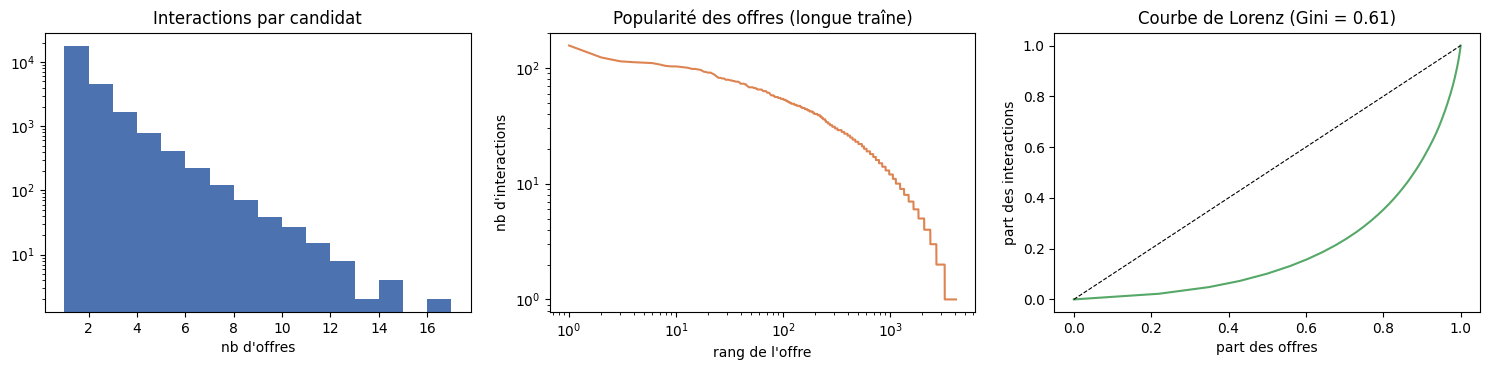

In [11]:
per_u = inter.groupby("u").size(); per_i = inter.groupby("j").size()
print("Candidats avec une seule interaction : %.1f %%" % (100 * (per_u == 1).mean()))
print("Répartition interactions/candidat :", per_u.describe()[["mean", "50%", "max"]].round(2).to_dict())
print("Répartition interactions/offre    :", per_i.describe()[["mean", "50%", "max"]].round(2).to_dict())

# Concentration de la popularité (courbe de Lorenz + indice de Gini)
x = np.sort(per_i.values); lorenz = np.cumsum(x) / x.sum()
gini = 1 - 2 * np.trapezoid(lorenz, dx=1 / len(x))
top10 = np.sort(per_i.values)[::-1][: max(1, len(per_i) // 10)].sum() / per_i.sum()
print(f"Gini de la popularité des offres = {gini:.3f} ; les 10 % d'offres les plus populaires = {100*top10:.1f} % des interactions")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(per_u, bins=range(1, per_u.max() + 2), log=True, color="#4C72B0"); ax[0].set_title("Interactions par candidat"); ax[0].set_xlabel("nb d'offres")
ax[1].plot(np.arange(1, len(per_i) + 1), np.sort(per_i.values)[::-1], color="#DD8452"); ax[1].set_yscale("log"); ax[1].set_xscale("log")
ax[1].set_title("Popularité des offres (longue traîne)"); ax[1].set_xlabel("rang de l'offre"); ax[1].set_ylabel("nb d'interactions")
ax[2].plot(np.linspace(0, 1, len(x)), lorenz, color="#55A868"); ax[2].plot([0, 1], [0, 1], "k--", lw=.8)
ax[2].set_title(f"Courbe de Lorenz (Gini = {gini:.2f})"); ax[2].set_xlabel("part des offres"); ax[2].set_ylabel("part des interactions")
plt.tight_layout(); plt.savefig(f"{FIG}/popularite.png", dpi=150); plt.show()

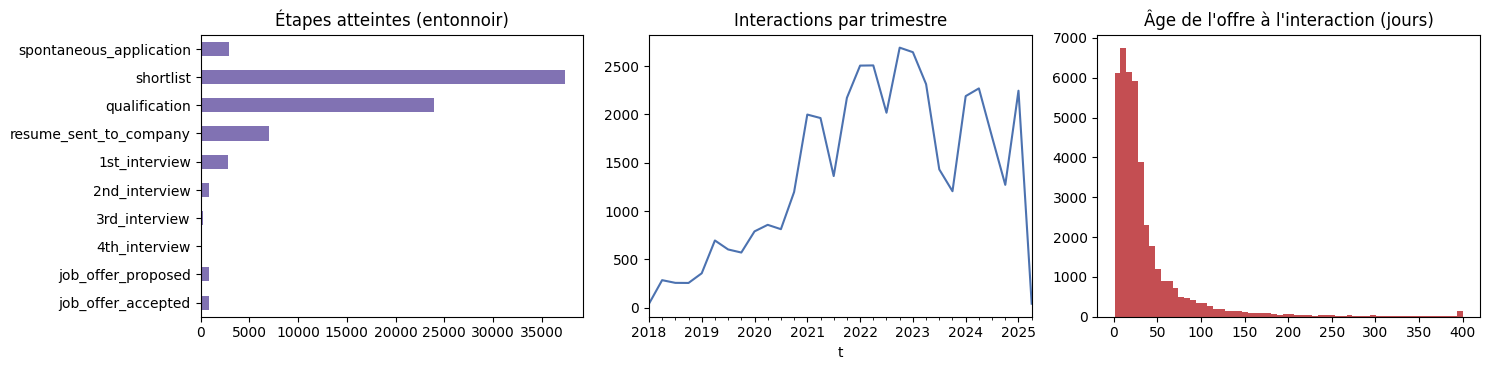

Quantiles de l'âge des offres à l'interaction : [ 22.  40.  81. 124.]


In [12]:
# Entonnoir de recrutement : combien d'interactions atteignent chaque étape ?
raw = D.raw_history
funnel = pd.Series({c.replace("_date", ""): raw[c].notna().sum() for c in STAGE_COLS if c in raw})
months = pd.to_datetime(inter.t, unit="D").dt.to_period("Q").value_counts().sort_index()

# Âge de l'offre au moment de l'interaction → durée de vie d'une offre
age = inter.t.values - jobs.create_day.values[inter.j.values]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
funnel.plot.barh(ax=ax[0], color="#8172B3"); ax[0].invert_yaxis(); ax[0].set_title("Étapes atteintes (entonnoir)")
months.plot(ax=ax[1], color="#4C72B0"); ax[1].set_title("Interactions par trimestre")
ax[2].hist(np.clip(age, -30, 400), bins=60, color="#C44E52"); ax[2].set_title("Âge de l'offre à l'interaction (jours)")
plt.tight_layout(); plt.savefig(f"{FIG}/entonnoir_temps.png", dpi=150); plt.show()
print("Quantiles de l'âge des offres à l'interaction :", np.percentile(age[age >= 0], [50, 75, 90, 95]).round())

In [13]:
# Valeurs manquantes des principaux attributs (justifie la gestion de l'« inconnu » dans le moteur à connaissances)
cols = ["skills", "expertise_area", "job_category", "years_experience", "contract_type", "zipcode",
        "llm_highest_diploma", "llm_required_lowest_diploma", "llm_seniority_level", "llm_hard_skills"]
miss = pd.DataFrame({"candidats (%)": [100 * cand[c].isna().mean() if c in cand else np.nan for c in cols],
                     "offres (%)": [100 * jobs[c].isna().mean() if c in jobs else np.nan for c in cols]}, index=cols).round(1)
miss

,candidats (%),offres (%)
skills,11.4,2.2
expertise_area,8.0,30.6
job_category,26.8,78.6
years_experience,83.5,88.9
contract_type,14.9,0.0
zipcode,41.6,2.1
llm_highest_diploma,0.0,NaN
llm_required_lowest_diploma,NaN,0.0
llm_seniority_level,0.0,0.0
llm_hard_skills,12.1,0.3


## 3. Découpage temporel train / validation / test

* **Test** = les 20 % d'interactions les plus récentes (découpage chronologique : pas de fuite du futur).
* **Validation** = les 10 % les plus récents de l'entraînement, pour régler les hybrides (poids, seuils).
* À une date *t*, un moteur ne voit **que les interactions antérieures à t** (comme un système en production) ;
  les paramètres appris (IDF du TF-IDF, régression logistique, poids) sont figés à la fin de l'entraînement.
* **Offres candidates** à la date *t* : offres créées depuis moins de *W* jours, avec *W* = quantile 95 % de
  l'âge des offres au moment des candidatures (mesuré sur l'entraînement). On exclut les offres déjà vues par le candidat.

In [14]:
train, test = temporal_split(inter, 0.8)
fit, val = temporal_split(train, 0.9)
W = estimate_pool_window(train, jobs.create_day.values, q=0.95)
train_end = int(train.t.max())
print(f"train={len(train)}  (dont validation={len(val)})  test={len(test)}  |  fenêtre d'activité W={W} jours")
print("Fin de l'entraînement :", pd.to_datetime(train_end, unit="D").date())

hist = History(inter, n_u, n_i)              # interrogé uniquement « avant t »
pool = JobPool(jobs.create_day.values.astype(int), W)
prof = Profiles(cand, jobs, fit_cutoff_day=train_end)
ctx = Context(prof, hist, pop_window=30, profile_beta=0.5, knn_k=50)
pool_fn = make_pool_fn(ctx, pool)

q_train, q_val, q_test = build_queries(train), build_queries(val), build_queries(test)
def describe(q, name):
    cold_u = np.mean([len(hist.items_of(u, t)) == 0 for u, t in zip(q.u, q.t)])
    cold_i = np.mean([all(len(hist.users_of(j, t)) == 0 for j in js) for js, t in zip(q.true_items, q.t)])
    in_pool = np.mean([np.isin(js, pool.at(t)).any() for js, t in zip(q.true_items, q.t)])
    sizes = [len(pool.at(t)) for t in q.t[:: max(1, len(q) // 300)]]
    return {"requêtes": len(q), "candidats nouveaux (%)": 100 * cold_u, "offres vraies sans historique (%)": 100 * cold_i,
            "offre vraie dans l'espace actif (%)": 100 * in_pool, "taille moyenne de l'espace": np.mean(sizes)}
pd.DataFrame({"validation": describe(q_val, "val"), "test": describe(q_test, "test")}).round(1)

train=33046  (dont validation=3305)  test=8262  |  fenêtre d'activité W=101 jours
Fin de l'entraînement : 2024-03-09


,validation,test
requêtes,3295.0,8216.0
candidats nouveaux (%),67.2,66.2
offres vraies sans historique (%),11.5,5.7
offre vraie dans l'espace actif (%),94.7,84.9
taille moyenne de l'espace,194.5,140.6


Le cold-start n'est pas une expérience artificielle ici : la grande majorité des requêtes de test concernent un candidat
**sans aucun historique** et/ou une offre **jamais vue**. C'est la difficulté centrale du recrutement (marché biface, entités éphémères).

## 4. Les moteurs de base

| Moteur | Idée | Fonctionne pour un nouveau candidat ? | … une nouvelle offre ? |
|---|---|---|---|
| **Popularité** (baseline) | offres ayant reçu le plus de candidatures sur les 30 derniers jours | oui | non |
| **Contenu** (TF-IDF) | cosinus entre profil (compétences, domaines, soft skills) du candidat et de l'offre ; profil enrichi des offres passées | oui | oui |
| **Collaboratif** (item-kNN) | offres co-positionnées avec celles du candidat (cosinus binaire) | **non** | non |
| **Connaissances** | part des contraintes satisfaites : diplôme, expérience, séniorité, lieu/télétravail, contrat, langues, management | oui | oui |

In [15]:
# Exemple sur une requête de validation
u, t, true = int(q_val.u.iloc[0]), int(q_val.t.iloc[0]), q_val.true_items.iloc[0]
p = pool_fn(u, t); comp = components(ctx, u, t, p)
print(f"candidat {u}, {len(p)} offres actives, historique = {comp['n_past']} offre(s)")
for k in ["pop", "cb", "cf", "kb", "meta"]:
    order = np.argsort(-comp[k]); r = np.flatnonzero(np.isin(p[order], true))
    print(f"  {k:5s} rang de l'offre vraie : {r[0]+1 if len(r) else '—'}")

candidat 23234, 206 offres actives, historique = 1 offre(s)
  pop   rang de l'offre vraie : 37
  cb    rang de l'offre vraie : 3
  cf    rang de l'offre vraie : 1
  kb    rang de l'offre vraie : 49
  meta  rang de l'offre vraie : 1


## 5. Réglage des hybrides sur la validation

In [16]:
qv = q_val.sample(min(MAX_VAL_QUERIES, len(q_val)), random_state=SEED).sort_values("t")
t0 = time.time(); cached_val = precompute(ctx, qv, pool_fn); print(f"{len(cached_val)} requêtes précalculées en {time.time()-t0:.0f}s")

# Base : NDCG@10 de chaque moteur seul
base_val = {k: quick_ndcg(cached_val, lambda c, k=k: c[k]) for k in BASE_KEYS}
print("NDCG@10 validation par moteur :", {k: round(v, 4) for k, v in base_val.items()})

1500 requêtes précalculées en 9s
NDCG@10 validation par moteur : {'pop': 0.1619, 'cb': 0.3738, 'cf': 0.1136, 'kb': 0.0648, 'meta': 0.4224}


In [17]:
# H1 — Pondéré : recherche exhaustive des poids (pas de 0.1, somme = 1) qui maximisent NDCG@10
t0 = time.time()
grid = [(quick_ndcg(cached_val, lambda c, w=w: weighted(c, w)), w) for w in weight_grid(("pop", "cb", "cf", "kb"), 0.1)]
grid.sort(key=lambda x: -x[0]); W_BEST = grid[0][1]
print(f"{len(grid)} combinaisons en {time.time()-t0:.0f}s — meilleurs poids : {W_BEST}  NDCG@10={grid[0][0]:.4f}")
pd.DataFrame([dict(ndcg=s, **w) for s, w in grid[:5]])

286 combinaisons en 71s — meilleurs poids : {'pop': 0.2, 'cb': 0.30000000000000004, 'cf': 0.2, 'kb': 0.30000000000000004}  NDCG@10=0.4863


,ndcg,pop,cb,cf,kb
0,0.4863,0.2,0.3,0.2,0.3
1,0.4836,0.2,0.3,0.3,0.2
2,0.4835,0.1,0.2,0.5,0.2
3,0.4834,0.1,0.2,0.4,0.3
4,0.4815,0.2,0.4,0.2,0.2


In [18]:
# H2 — Commutation (règle classique) : collaboratif si le candidat a au moins n_min offres
# dans son historique ET que le CF produit un signal, sinon contenu. On règle n_min.
# (Le méta-niveau H7, déjà un hybride, est volontairement exclu des moteurs commutables.)
cold_c = [c for c in cached_val if c[4]["n_past"] == 0]; warm_c = [c for c in cached_val if c[4]["n_past"] > 0]
print("Validation, candidats connus — NDCG@10 CF = %.4f, contenu = %.4f" % (
    quick_ndcg(warm_c, lambda c: c["cf"]), quick_ndcg(warm_c, lambda c: c["cb"])))
SW = max(({"n_min": n, "warm": "cf", "cold": "cb"} for n in (1, 2, 3, 4)),
         key=lambda cfg: quick_ndcg(cached_val, lambda c: switching(c, cfg)))
print("Commutation retenue :", SW, f"({len(warm_c)} requêtes 'connues' / {len(cold_c)} 'nouvelles' en validation)")

# H4 — Cascade : seuil d'éligibilité ; second étage = pondération sans le moteur à connaissances
second = {k: v for k, v in W_BEST.items() if k != "kb"} or {"cb": 1.0}
if sum(second.values()) == 0: second = {"cb": 1.0}
TAU = max((0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8), key=lambda tau: quick_ndcg(cached_val, lambda c: cascade(c, tau, second)))
elim = np.mean([np.mean(c[4]["kb"] < TAU) for c in cached_val])
print("Cascade : seuil τ =", TAU, "| second étage :", second, f"| offres éliminées en moyenne : {100*elim:.1f} %")

Validation, candidats connus — NDCG@10 CF = 0.2961, contenu = 0.3115
Commutation retenue : {'n_min': 1, 'warm': 'cf', 'cold': 'cb'} (491 requêtes 'connues' / 1009 'nouvelles' en validation)
Cascade : seuil τ = 0.3 | second étage : {'pop': 0.2, 'cb': 0.30000000000000004, 'cf': 0.2} | offres éliminées en moyenne : 2.1 %


Cascade : seuil τ = 0.3 | second étage : {'pop': 0.2, 'cb': 0.30000000000000004, 'cf': 0.2} | offres éliminées en moyenne : 2.1 %


In [19]:
# H5 / H6 — régression logistique entraînée sur des requêtes de l'entraînement (échantillonnage négatif 1:20)
t0 = time.time()
Xr, Xa, y = build_ltr_dataset(ctx, q_train, pool_fn, n_neg=20, seed=SEED, max_queries=6000)
ltr_raw = LTRHybrid(augmented=False).fit(Xr, y)
ltr_aug = LTRHybrid(augmented=True).fit(Xa, y)
print(f"{len(y)} couples ({y.sum()} positifs) en {time.time()-t0:.0f}s")
# Remarque : les requêtes de validation font partie de l'entraînement du modèle ; ce chiffre est donc optimiste.
for name, m, aug in [("comb. features", ltr_raw, False), ("augm. features", ltr_aug, True)]:
    v = np.mean([ndcg_for(
        np.argsort(-m.score_from_features(pair_features(ctx, u, t, p, c, augmented=aug))), p, tr, 10)
        for (u, t, p, tr, c) in cached_val])
    print(f"NDCG@10 validation ({name}) : {v:.4f}")

119517 couples (5717 positifs) en 50s
NDCG@10 validation (comb. features) : 0.4769
NDCG@10 validation (augm. features) : 0.6023


NDCG@10 validation (augm. features) : 0.6124


## 6. Évaluation sur le test

In [20]:
def ltr_fn(model, aug):
    return lambda c, u, t, p: model.score_from_features(pair_features(ctx, u, t, p, c, augmented=aug))

METHODS = {
    "Popularité (baseline)":       lambda c, u, t, p: c["pop"],
    "Contenu":                     lambda c, u, t, p: c["cb"],
    "Collaboratif":                lambda c, u, t, p: c["cf"],
    "Connaissances":               lambda c, u, t, p: c["kb"],
    "H1 Pondéré":                  lambda c, u, t, p: weighted(c, W_BEST),
    "H2 Commutation":              lambda c, u, t, p: switching(c, SW),
    "H3 Mixte":                    lambda c, u, t, p: mixed(c),
    "H4 Cascade":                  lambda c, u, t, p: cascade(c, TAU, second),
    "H5 Combinaison de features":  ltr_fn(ltr_raw, False),
    "H6 Augmentation de features": ltr_fn(ltr_aug, True),
    "H7 Méta-niveau":              lambda c, u, t, p: c["meta"],
}
qt = q_test if MAX_TEST_QUERIES is None else q_test.sample(MAX_TEST_QUERIES, random_state=SEED).sort_values("t")
t0 = time.time(); cached_test = precompute(ctx, qt, pool_fn); print(f"{len(cached_test)} requêtes de test précalculées en {time.time()-t0:.0f}s")
t0 = time.time(); res = evaluate(cached_test, METHODS, ctx, ks=(5, K)); print(f"évaluation en {time.time()-t0:.0f}s")
summary = summarize(res, cached_test, ks=(5, K))
summary.to_csv("resultats_test.csv")
summary

8216 requêtes de test précalculées en 42s
évaluation en 121s


,P@5,R@5,NDCG@5,HR@5,P@10,R@10,NDCG@10,HR@10,MRR,Couverture,Diversité,Nouveauté,HR@10 offres nouvelles,n_requêtes
Popularité (baseline),0.0292,0.1458,0.0955,0.1461,0.0235,0.2347,0.1241,0.2353,0.1120,0.2853,0.9060,10.5730,0.0000,8216.0
Contenu,0.0772,0.3848,0.2706,0.3857,0.0510,0.5087,0.3107,0.5096,0.2633,0.9922,0.7663,12.6669,0.5966,8216.0
Collaboratif,0.0291,0.1446,0.1150,0.1451,0.0183,0.1817,0.1270,0.1823,0.1238,0.6630,0.8987,12.5453,0.0794,8216.0
Connaissances,0.0130,0.0651,0.0394,0.0651,0.0127,0.1266,0.0591,0.1269,0.0595,0.6834,0.9025,12.4742,0.1481,8216.0
H1 Pondéré,0.0969,0.4837,0.3731,0.4843,0.0589,0.5877,0.4071,0.5886,0.3618,0.9859,0.8157,11.6735,0.5150,8216.0
H2 Commutation,0.0839,0.4185,0.3092,0.4193,0.0533,0.5314,0.3459,0.5323,0.3007,0.9922,0.7732,12.5902,0.5880,8216.0
H3 Mixte,0.0852,0.4251,0.2978,0.4260,0.0545,0.5433,0.3359,0.5443,0.2847,0.9922,0.8483,11.5065,0.4335,8216.0
H4 Cascade,0.0937,0.4675,0.3565,0.4682,0.0576,0.5747,0.3913,0.5756,0.3462,0.9906,0.8074,11.6615,0.4828,8216.0
H5 Combinaison de features,0.0907,0.4523,0.3431,0.4530,0.0561,0.5601,0.3780,0.5609,0.3331,0.8715,0.8583,11.8540,0.4614,8216.0
H6 Augmentation de features,0.1176,0.5870,0.4745,0.5878,0.0670,0.6683,0.5011,0.6691,0.4550,0.9122,0.8287,12.4351,0.6888,8216.0


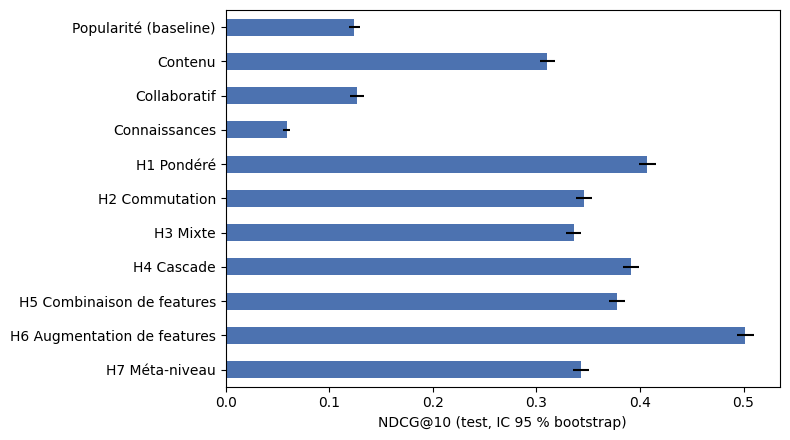

,NDCG@10,IC bas,IC haut
Popularité (baseline),0.1241,0.1190,0.1301
Contenu,0.3107,0.3034,0.3185
Collaboratif,0.1270,0.1204,0.1341
Connaissances,0.0591,0.0553,0.0626
H1 Pondéré,0.4071,0.3995,0.4153
H2 Commutation,0.3459,0.3381,0.3539
H3 Mixte,0.3359,0.3291,0.3433
H4 Cascade,0.3913,0.3836,0.3995
H5 Combinaison de features,0.3780,0.3699,0.3855
H6 Augmentation de features,0.5011,0.4935,0.5097


In [21]:
# Intervalles de confiance à 95 % (bootstrap sur les requêtes) pour NDCG@10
rng = np.random.default_rng(SEED)
nq = res.q.nunique(); boots = rng.integers(0, nq, size=(300, nq))
ci = {}
for m, g in res.groupby("method", sort=False):
    v = g.sort_values("q")[f"NDCG@{K}"].values
    b = v[boots].mean(axis=1); ci[m] = (v.mean(), *np.percentile(b, [2.5, 97.5]))
ci = pd.DataFrame(ci, index=["NDCG@10", "IC bas", "IC haut"]).T
ax = ci["NDCG@10"].plot.barh(xerr=[ci["NDCG@10"] - ci["IC bas"], ci["IC haut"] - ci["NDCG@10"]], figsize=(8, 4.5), color="#4C72B0")
ax.invert_yaxis(); ax.set_xlabel("NDCG@10 (test, IC 95 % bootstrap)"); plt.tight_layout(); plt.savefig(f"{FIG}/ndcg_test.png", dpi=150); plt.show()
ci

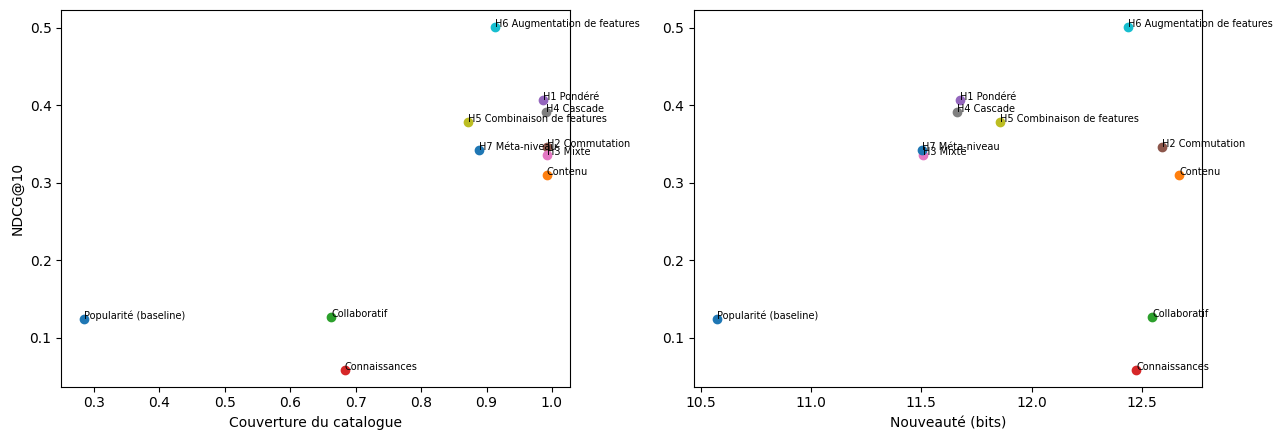

In [22]:
# Précision vs au-delà de la précision
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for m, r in summary.iterrows():
    ax[0].scatter(r["Couverture"], r[f"NDCG@{K}"]); ax[0].annotate(m, (r["Couverture"], r[f"NDCG@{K}"]), fontsize=7)
    ax[1].scatter(r["Nouveauté"], r[f"NDCG@{K}"]); ax[1].annotate(m, (r["Nouveauté"], r[f"NDCG@{K}"]), fontsize=7)
ax[0].set_xlabel("Couverture du catalogue"); ax[1].set_xlabel("Nouveauté (bits)"); ax[0].set_ylabel("NDCG@10")
plt.tight_layout(); plt.savefig(f"{FIG}/compromis.png", dpi=150); plt.show()

## 7. Cold-start

Trois analyses :
1. **Nouveaux candidats** (aucune interaction avant *t*) vs **candidats connus** — partition naturelle du test.
2. **Nouvelles offres** : HR@10 calculé uniquement sur les offres vraies qui n'avaient reçu aucune candidature avant *t*.
3. **Nouveaux candidats simulés** : on reprend les requêtes des candidats connus en **masquant leur historique** ;
   on mesure ce que chaque méthode perd quand le candidat devient « nouveau ».

In [23]:
cols = [f"P@{K}", f"R@{K}", f"NDCG@{K}", f"HR@{K}", "MRR", f"HR@{K} offres nouvelles", "n_requêtes"]
cold_tab = summarize(res, cached_test, ks=(5, K), group="cold")[cols]
warm_tab = summarize(res, cached_test, ks=(5, K), group="warm")[cols]
display(pd.concat({"Nouveaux candidats": cold_tab, "Candidats connus": warm_tab}, axis=1).round(4))

Nouveaux candidats                                                                   Candidats connus                          \
                                          P@10    R@10 NDCG@10   HR@10     MRR HR@10 offres nouvelles n_requêtes             P@10    R@10 NDCG@10   HR@10   
Popularité (baseline)                   0.0239  0.2382  0.1279  0.2385  0.1152                 0.0000     5438.0           0.0229  0.2279  0.1167  0.2289   
Contenu                                 0.0477  0.4766  0.2953  0.4768  0.2526                 0.5949     5438.0           0.0575  0.5715  0.3409  0.5738   
Collaboratif                            0.0070  0.0701  0.0297  0.0702  0.0331                 0.0854     5438.0           0.0402  0.4002  0.3175  0.4017   
Connaissances                           0.0128  0.1282  0.0619  0.1284  0.0629                 0.1582     5438.0           0.0124  0.1234  0.0538  0.1242   
H1 Pondéré                              0.0551  0.5512  0.3726  0.5513  0.3288                 0.5222     5438.0           0.0663  0.6592  0.4745  0.6616   
H2 Commutation                          0.0477  0.4766  0.2953  0.4768  0.2526                 0.5949     5438.0           0.0643  0.6388  0.4447  0.6407   
H3 Mixte                                0.0533  0.5326  0.3367  0.5329  0.2878                 0.4430     5438.0           0.0567  0.5641  0.3342  0.5666   
H4 Cascade                              0.0534  0.5337  0.3520  0.5338  0.3085                 0.4968     5438.0           0.0659  0.6549  0.4682  0.6573   
H5 Combinaison de features              0.0565  0.5643  0.3929  0.5644  0.3502                 0.4810     5438.0           0.0555  0.5520  0.3490  0.5540   
H6 Augmentation de features             0.0636  0.6353  0.4859  0.6353  0.4459                 0.6677     5438.0           0.0737  0.7331  0.5307  0.7351   
H7 Méta-niveau                          0.0504  0.5033  0.3497  0.5037  0.3113                 0.0190     5438.0           0.0554  0.5506  0.3298  0.5533   

                                                                       
                                MRR HR@10 offres nouvelles n_requêtes  
Popularité (baseline)        0.1058                 0.0000     2778.0  
Contenu                      0.2842                 0.6000     2778.0  
Collaboratif                 0.3015                 0.0667     2778.0  
Connaissances                0.0530                 0.1267     2778.0  
H1 Pondéré                   0.4265                 0.5000     2778.0  
H2 Commutation               0.3948                 0.5733     2778.0  
H3 Mixte                     0.2786                 0.4133     2778.0  
H4 Cascade                   0.4202                 0.4533     2778.0  
H5 Combinaison de features   0.2995                 0.4200     2778.0  
H6 Augmentation de features  0.4729                 0.7333     2778.0  
H7 Méta-niveau               0.2728                 0.0000     2778.0

In [24]:
warm_q = pd.DataFrame([(u, t, tr) for (u, t, p, tr, c) in cached_test if c["n_past"] > 0], columns=["u", "t", "true_items"])
if len(warm_q):
    cached_hidden = precompute(ctx, warm_q, pool_fn, hide_user_history=True)
    cached_warm = [c for c in cached_test if c[4]["n_past"] > 0]
    r_real = summarize(evaluate(cached_warm, METHODS, ctx, ks=(K,)), cached_warm, ks=(K,))[f"NDCG@{K}"]
    r_hide = summarize(evaluate(cached_hidden, METHODS, ctx, ks=(K,)), cached_hidden, ks=(K,))[f"NDCG@{K}"]
    sim = pd.DataFrame({"avec historique": r_real, "historique masqué": r_hide})
    sim["perte (%)"] = 100 * (sim["historique masqué"] - sim["avec historique"]) / sim["avec historique"].replace(0, np.nan)
    display(sim.round(4))
else:
    print("Aucun candidat connu dans le test.")

,avec historique,historique masqué,perte (%)
Popularité (baseline),0.1167,0.1167,0.0000
Contenu,0.3409,0.2467,-27.6330
Collaboratif,0.3175,0.0295,-90.6997
Connaissances,0.0538,0.0538,0.0000
H1 Pondéré,0.4745,0.3130,-34.0286
H2 Commutation,0.4447,0.2467,-44.5339
H3 Mixte,0.3342,0.2633,-21.2184
H4 Cascade,0.4682,0.2977,-36.4095
H5 Combinaison de features,0.3490,0.3490,0.0000
H6 Augmentation de features,0.5307,0.4332,-18.3686


## 8. Interprétabilité et explications

In [25]:
print("Poids du pondéré :", W_BEST, "| Commutation :", SW, "| Cascade τ :", TAU)
coef = pd.DataFrame({"combinaison (H5)": pd.Series(ltr_raw.coefficients()),
                     "augmentation (H6)": pd.Series(ltr_aug.coefficients())})
coef.sort_values("augmentation (H6)", key=abs, ascending=False)

Poids du pondéré : {'pop': 0.2, 'cb': 0.30000000000000004, 'cf': 0.2, 'kb': 0.30000000000000004} | Commutation : {'n_min': 1, 'warm': 'cf', 'cold': 'cb'} | Cascade τ : 0.3


,combinaison (H5),augmentation (H6)
age_offre,-1.353,-1.349
log_pop_recente,0.721,0.940
score_contenu,NaN,0.730
score_meta,NaN,0.691
c_contrat,0.844,0.627
log_pop_totale,0.292,-0.612
log_hist_candidat,-0.112,-0.453
score_kb,NaN,0.428
score_cf,NaN,0.324
c_langues,-0.069,-0.231


In [26]:
# Exemple d'explication (format affiché dans la démo Streamlit)
u, t, p, true, c = next(x for x in cached_test if np.isin(x[3], x[2]).any())
s = METHODS["H6 Augmentation de features"](c, u, t, p)
order = np.argsort(-s)[:3]
for rank, idx in enumerate(order, 1):
    e = explain(ctx, c, p, idx, u, t)
    print(f"#{rank} offre {jobs.job_id[e['job']][:10]}… {'(VRAIE)' if e['job'] in true else ''}")
    for r in e["reasons"]: print("   +", r)
    for w in e["warnings"]: print("   −", w)

#1 offre 3798… 
   + 2/5 compétences demandées présentes dans votre profil (java, python).
   + Critères respectés : diplôme, expérience, séniorité, contrat, langues.
   + Des candidats au profil proche du vôtre ont été positionnés sur cette offre.
   + Offre active : 14 candidature(s) ces 30 derniers jours.
   − Compétences à acquérir : gitlab, go, python programming.
   − Information manquante pour : localisation.
#2 offre 2573… 
   + 1/3 compétences demandées présentes dans votre profil (java).
   + Critères respectés : diplôme, expérience, séniorité, contrat, langues.
   + Des candidats au profil proche du vôtre ont été positionnés sur cette offre.
   + Offre active : 22 candidature(s) ces 30 derniers jours.
   − Compétences à acquérir : javascript, react.js.
   − Information manquante pour : localisation.
#3 offre 2818… 
   + 2/5 compétences demandées présentes dans votre profil (angular, java).
   + Critères respectés : diplôme, expérience, séniorité, contrat, langues.
   + Des c

In [27]:
# Sauvegarde des modèles réglés pour la démo Streamlit (app.py)
import joblib
joblib.dump({"W_BEST": W_BEST, "SW": SW, "TAU": TAU, "second": second, "ltr_raw": ltr_raw, "ltr_aug": ltr_aug,
             "window": W, "train_end": train_end, "summary": summary}, "models.joblib")
print("models.joblib écrit")

models.joblib écrit


## 9. Démonstration dans le notebook
La même logique que l'application Streamlit : choisir un candidat (réel ou nouveau), une stratégie, et obtenir le top-K
expliqué. Le score affiché est une correspondance relative, **pas une probabilité d'embauche**.

In [28]:
def job_title(j: int) -> str:
    # JTH ne fournit pas d'intitulé : on en compose un (domaine — séniorité)
    dom = prof.tokens("j", "dom", j)
    sen = jobs.iloc[j].get("llm_seniority_level")
    return f"{(dom[0] if dom else 'offre').title()} — {sen if isinstance(sen, str) else '?'}"


def recommend(u: int, t: int, method: str = "H6 Augmentation de features", k: int = 10, true_items=()):
    p = pool_fn(u, t)
    c = components(ctx, u, t, p)
    s = METHODS[method](c, u, t, p)
    order = rank_order(s, p)[:k]
    match = 100 * (s[order] - s.min()) / (s.max() - s.min() + 1e-12)
    print(f"Candidat {u} · {pd.to_datetime(t, unit='D').date()} · {len(p)} offres actives · "
          f"historique : {c['n_past']} offre(s) · méthode : {method}\n")
    for rank, (idx, m) in enumerate(zip(order, match), 1):
        e = explain(ctx, c, p, idx, u, t)
        flag = "  ✓ obtenue en réalité" if e["job"] in true_items else ""
        print(f"#{rank:<2} {job_title(e['job'])}  ({m:.0f} %){flag}")
        for r in e["reasons"][:3]: print("     +", r)
        for w in e["warnings"][:2]: print("     −", w)


# Exemple 1 : un vrai candidat du test, à la date de sa requête
row = q_test.iloc[42]
recommend(int(row.u), int(row.t), true_items=row.true_items, k=5)

Candidat 12011 · 2024-03-10 · 181 offres actives · historique : 0 offre(s) · méthode : H6 Augmentation de features

#1  Digital Project Manager — Senior  (100 %)  ✓ obtenue en réalité
     + 2/4 compétences demandées présentes dans votre profil (microsoft office, sales).
     + Critères respectés : diplôme, expérience, séniorité, contrat, langues.
     + Des candidats au profil proche du vôtre ont été positionnés sur cette offre.
     − Critères non respectés : localisation.
     − Compétences à acquérir : communication, marketing.
#2  Development — Senior  (54 %)
     + 1/4 compétences demandées présentes dans votre profil (java).
     + Critères respectés : diplôme, expérience, séniorité, localisation, contrat, langues.
     + Des candidats au profil proche du vôtre ont été positionnés sur cette offre.
     − Compétences à acquérir : confluence, jira, sql.
#3  Cloud & Infrastructure — Senior  (53 %)
     + 3/10 compétences demandées présentes dans votre profil (google cloud platform,

In [29]:
# Exemple 2 : un NOUVEAU profil saisi à la main (cold-start utilisateur) — aucun réapprentissage
new_u = add_candidate(prof, {
    "skills": "python;sql;machine learning;pandas", "llm_hard_skills": "python;sql;machine learning",
    "expertise_area": "data science", "llm_job_category": "data science",
    "llm_highest_diploma": "Master", "llm_years_of_work_experience": "2-5",
    "llm_seniority_level": "Junior", "contract_type": "permanent", "zipcode": "75",
    "llm_languages_spoken": "french;english", "llm_management_experience": False})
recommend(new_u, int(q_test.t.iloc[-1]), k=5)

Candidat 37554 · 2025-04-21 · 76 offres actives · historique : 0 offre(s) · méthode : H6 Augmentation de features

#1  Backend Developer — Mid  (100 %)
     + 1/2 compétences demandées présentes dans votre profil (python).
     + Critères respectés : diplôme, expérience, séniorité, localisation, contrat, langues.
     + Des candidats au profil proche du vôtre ont été positionnés sur cette offre.
     − Compétences à acquérir : python programming.
#2  Data — Senior  (100 %)
     + 2/2 compétences demandées présentes dans votre profil (python, sql).
     + Critères respectés : diplôme, localisation, contrat, langues.
     + Des candidats au profil proche du vôtre ont été positionnés sur cette offre.
     − Critères non respectés : expérience, séniorité.
#3  Cloud & Infrastructure — Mid  (70 %)
     + 1/2 compétences demandées présentes dans votre profil (python).
     + Critères respectés : diplôme, expérience, séniorité, localisation, contrat, langues.
     + Des candidats au profil pro

## Conclusion
Les tableaux ci-dessus sont repris et discutés dans le rapport : la dimension temporelle (offres actives, popularité récente)
et le cold-start dominent ce dataset ; l'augmentation de features (H6), qui apprend à combiner contenu, contraintes,
popularité récente et voisinage, dépasse nettement chaque moteur seul.